# Pengkalan Chepa water-quality analysis: major revision
Omar Kairan, Fukayhah@Fatiha Suhami and Nurul Hafizah Azizan

Run these cells in order. Place the authorised DOE workbook beside this notebook and the revised Python module. The workflow reproduces the JMCS major-revision analyses, including the gap statistic, cluster-specific silhouettes and SDOclust parameter checks.


## 1 Install packages once
Uncomment the next command if packages are not installed. Restart the kernel after installation, then continue. Python 3.12 and the official `sdoclust==0.5.1` package are required for the parameter analysis.


In [2]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2 Paths and imports
Change EXCEL to your actual workbook path if necessary. On Windows, use a raw path such as `Path(r"C:\Users\Omar\Documents\LAMPIRAN A - KELANTAN.xlsx")`.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
from pengkalan_chepa_clustering import (
    load_data, numeric, transform, fit, metrics, run_analysis,
    gap_statistic, hopkins_statistic, per_cluster_silhouettes,
    sdoclust_parameter_grid, FEATURES, METHODS
)
EXCEL = Path('LAMPIRAN A - KELANTAN.xlsx')
OUT = Path('results_rerun')
assert EXCEL.is_file(), f'Workbook not found: {EXCEL.resolve()}'


Matplotlib is building the font cache; this may take a moment.


## 3 Audit source records
The raw strings, reporting limits and censoring flags are retained. Censored numeric entries are deliberately blank before the numerical working representation is constructed.

In [4]:
raw = load_data(EXCEL)
display(raw[['record_id','station','date','year']].head())
display(pd.DataFrame([{'variable': c, 'missing': int((raw[c].isna() & ~raw[c+'_censored']).sum()), 'censored': int(raw[c+'_censored'].sum())} for c in FEATURES]))
print('Source rows:',len(raw), 'Stations:',raw.station.nunique(), 'Dates:',raw.date.nunique())

,record_id,station,date,year
0,1,4DPCH001,2020-02-21,2020
1,2,4DPCH001,2020-06-21,2020
2,3,4DPCH001,2020-08-23,2020
3,4,4DPCH001,2020-10-21,2020
4,5,4DPCH001,2020-11-27,2020


,variable,missing,censored
0,DO,0,0
1,BOD,0,23
2,COD,0,0
3,SS,0,3
4,pH,0,0
5,NH3N,1,6


Source rows: 180 Stations: 6 Dates: 30


## 4 Complete records and transformations
Half-limit substitution is a primary working convention, not formal censored-data estimation. Four concentration variables are log-transformed; all six inputs are standardised. One genuinely missing record is excluded here and checked in sensitivity analysis.

In [5]:
working = numeric(raw, fraction=0.5)
keep = working.notna().all(axis=1)
X = working.loc[keep].reset_index(drop=True)
Z = transform(X)
display(raw.loc[~keep, ['station','date','DO_raw','pH_raw','NH3N_raw']])
print('Complete observations:',len(X))
display(X.describe().T)

,station,date,DO_raw,pH_raw,NH3N_raw
20,4DPCH004,2020-08-23,14.547,9.753,NaN


Complete observations: 179


,count,mean,std,min,25%,50%,75%,max
DO,179.0,4.832983,1.951604,1.168,3.1945,4.830,6.1390,11.456
BOD,179.0,4.181564,4.956467,0.500,1.5000,3.000,5.5000,51.000
COD,179.0,24.167598,14.172884,3.000,15.0000,23.000,32.0000,118.000
SS,179.0,48.650838,102.637847,0.500,8.0000,14.000,49.0000,872.000
pH,179.0,7.118659,0.547449,6.130,6.6925,7.061,7.4385,8.727
NH3N,179.0,1.610168,1.806010,0.005,0.2650,0.900,2.3350,9.490


## 5 Spearman correlation and PCA
The PCA display does not replace the six-dimensional clustering input.

In [6]:
from sklearn.decomposition import PCA
display(X.corr(method='spearman'))
pca = PCA().fit(Z)
display(pd.DataFrame({'PC':range(1,7),'variance_proportion':pca.explained_variance_ratio_, 'cumulative':np.cumsum(pca.explained_variance_ratio_)}))
display(pd.DataFrame(pca.components_.T,index=FEATURES,columns=[f'PC{i}' for i in range(1,7)]))

,DO,BOD,COD,SS,pH,NH3N
DO,1.000000,-0.275987,0.098369,0.184614,0.609278,-0.491535
BOD,-0.275987,1.000000,0.466053,-0.181105,-0.058567,0.638600
COD,0.098369,0.466053,1.000000,-0.159591,0.396329,0.226571
SS,0.184614,-0.181105,-0.159591,1.000000,-0.109315,-0.401521
pH,0.609278,-0.058567,0.396329,-0.109315,1.000000,-0.201969
NH3N,-0.491535,0.638600,0.226571,-0.401521,-0.201969,1.000000


,PC,variance_proportion,cumulative
0,1,0.372803,0.372803
1,2,0.290983,0.663786
2,3,0.148999,0.812785
3,4,0.084875,0.897660
4,5,0.058824,0.956484
5,6,0.043516,1.000000


,PC1,PC2,PC3,PC4,PC5,PC6
DO,-0.352269,0.517408,-0.077676,-0.515967,-0.535599,-0.221522
BOD,0.539160,0.183441,0.383534,-0.250838,-0.253424,0.633573
COD,0.330654,0.513277,0.235052,0.614550,-0.181632,-0.401626
SS,-0.358135,-0.018699,0.864268,-0.136982,0.287131,-0.152388
pH,-0.118890,0.658928,-0.206147,-0.027837,0.653372,0.285505
NH3N,0.577482,-0.025475,-0.046502,-0.523114,0.326467,-0.532423


## 6 Candidate clustering solutions
Retain a one-group SDOclust result if returned. Silhouette and DBI are undefined for one group. Conventional methods select k by maximum silhouette over k=2,...,6.

In [7]:
candidate_rows=[]
for method in METHODS:
    labels, candidates = fit(Z, method)
    candidate_rows.extend(candidates)
    print(method, metrics(Z,labels))
display(pd.DataFrame(candidate_rows))

SDOclust {'k': 1, 'noise': 0, 'coverage': 1.0, 'silhouette': nan, 'DBI': nan}
K-means {'k': 2, 'noise': 0, 'coverage': 1.0, 'silhouette': 0.23109382079912957, 'DBI': 1.6140061588799086}
Ward {'k': 2, 'noise': 0, 'coverage': 1.0, 'silhouette': 0.22177524280586738, 'DBI': 1.6466136425616307}


,method,k,noise,coverage,silhouette,DBI
0,SDOclust,1,0,1.0,NaN,NaN
1,K-means,2,0,1.0,0.231094,1.614006
2,K-means,3,0,1.0,0.223377,1.407102
3,K-means,4,0,1.0,0.224485,1.346463
4,K-means,5,0,1.0,0.224887,1.347024
5,K-means,6,0,1.0,0.227476,1.286437
6,Ward,2,0,1.0,0.221775,1.646614
7,Ward,3,0,1.0,0.205312,1.400099
8,Ward,4,0,1.0,0.204206,1.418652
9,Ward,5,0,1.0,0.185763,1.378826


## 7 Evidence for the number of groups
The gap statistic explicitly evaluates `k=1`. Per-cluster silhouettes describe the conditional two-group solutions. The full workflow below also runs 500 Hopkins replicates and 330 SDOclust parameter–seed combinations.


In [11]:
gap_preview = gap_statistic(Z, k_max=6, references=200)
display(gap_preview)
display(per_cluster_silhouettes(Z, X))


,k,log_Wk,gap,s_k,selected_by_1se
0,1,6.979145,0.843938,0.034499,True
1,2,6.686660,0.846582,0.033157,False
2,3,6.467565,0.849602,0.033223,False
3,4,6.327661,0.841409,0.032779,False
4,5,6.179190,0.886221,0.030673,False
5,6,6.076082,0.902977,0.029165,False


,method,cluster,n,mean_silhouette,median_silhouette,minimum,maximum,negative_n,negative_percent
0,K-means,C1,83,0.210949,0.217394,-0.004028,0.393594,1,1.204819
1,K-means,C2,96,0.248510,0.256571,0.006265,0.441021,0,0.000000
2,Ward,C1,92,0.209722,0.224439,-0.102190,0.390592,5,5.434783
3,Ward,C2,87,0.234521,0.237503,-0.059830,0.431347,5,5.747126


## 8 Run the complete reproducible workflow
This includes 200 date-block subsamples, 100 censoring draws, 200 gap references, 500 Hopkins replicates, 30 seeds for each of 11 SDOclust settings, station omission, missing-value and preprocessing sensitivities, and all exports. No command-line arguments are passed by the notebook.


In [12]:
analysis = run_analysis(
    EXCEL, out=OUT, repeats=200, draws=100,
    gap_references=200, hopkins_repeats=500, sdo_grid_seeds=30
)


{
  "n_source": 180,
  "n_complete": 179,
  "n_stations": 6,
  "n_dates": 30,
  "primary_method": "K-means",
  "repeats": 200,
  "censor_draws": 100,
  "gap_references": 200,
  "hopkins_repeats": 500,
  "sdo_grid_seeds": 30,
  "gap_selected_k": 1,
  "seed": 20261010,
  "source_sha256": "3b70f8ae9498205af30dee62667b971b899e00dfa6f3103c6ec9e080c03723be",
  "python": "3.11.0",
  "numpy": "2.3.5",
  "pandas": "2.2.3",
  "scipy": "1.17.0",
  "sklearn": "1.5.2",
  "sdoclust_external": true
}
  method  k  noise  coverage  silhouette      DBI
SDOclust  1      0       1.0         NaN      NaN
 K-means  2      0       1.0    0.231094 1.614006
    Ward  2      0       1.0    0.221775 1.646614
method
K-means     0.644232
SDOclust         NaN
Ward        0.344551
Name: ARI, dtype: float64


## 9 Inspect profiles, cluster evidence and stability
Percentiles describe perturbation spread, not inferential confidence intervals. SDOclust one-group comparisons do not establish useful cluster recovery.

In [13]:
for name in [
    'selected_metrics','gap_statistic','per_cluster_silhouette',
    'hopkins_summary','sdoclust_parameter_summary','cluster_medians',
    'cluster_by_station_percent','cluster_by_year_percent',
    'stability_summary','sensitivity','station_omission'
]:
    print('\n'+name)
    display(pd.read_csv(OUT/(name+'.csv')))
for name in ['censor_uniform_draws','seed_sensitivity']:
    t=pd.read_csv(OUT/(name+'.csv'))
    print('\n'+name)
    display(t.groupby('method').agg({'ARI':['min','median','max'],'k':['min','max']}))



selected_metrics


,method,k,noise,coverage,silhouette,DBI
0,SDOclust,1,0,1.0,NaN,NaN
1,K-means,2,0,1.0,0.231094,1.614006
2,Ward,2,0,1.0,0.221775,1.646614



gap_statistic


,k,log_Wk,gap,s_k,selected_by_1se
0,1,6.979145,0.843938,0.034499,True
1,2,6.686660,0.846582,0.033157,False
2,3,6.467565,0.849602,0.033223,False
3,4,6.327661,0.841409,0.032779,False
4,5,6.179190,0.886221,0.030673,False
5,6,6.076082,0.902977,0.029165,False



per_cluster_silhouette


,method,cluster,n,mean_silhouette,median_silhouette,minimum,maximum,negative_n,negative_percent
0,K-means,C1,83,0.210949,0.217394,-0.004028,0.393594,1,1.204819
1,K-means,C2,96,0.248510,0.256571,0.006265,0.441021,0,0.000000
2,Ward,C1,92,0.209722,0.224439,-0.102190,0.390592,5,5.434783
3,Ward,C2,87,0.234521,0.237503,-0.059830,0.431347,5,5.747126


... (16 outputs left out)


censor_uniform_draws


ARI                  k    
               min    median  max min max
method                                   
K-means   0.636183  1.000000  1.0   2   2
SDOclust  1.000000  1.000000  1.0   1   1
Ward      0.222055  0.768019  1.0   2   6


seed_sensitivity


ARI               k    
          min median  max min max
method                           
K-means   1.0    1.0  1.0   2   2
SDOclust  0.0    1.0  1.0   1   2

## 10 View manuscript figures
C1 and C2 are descriptive profiles, not official water-quality classes.

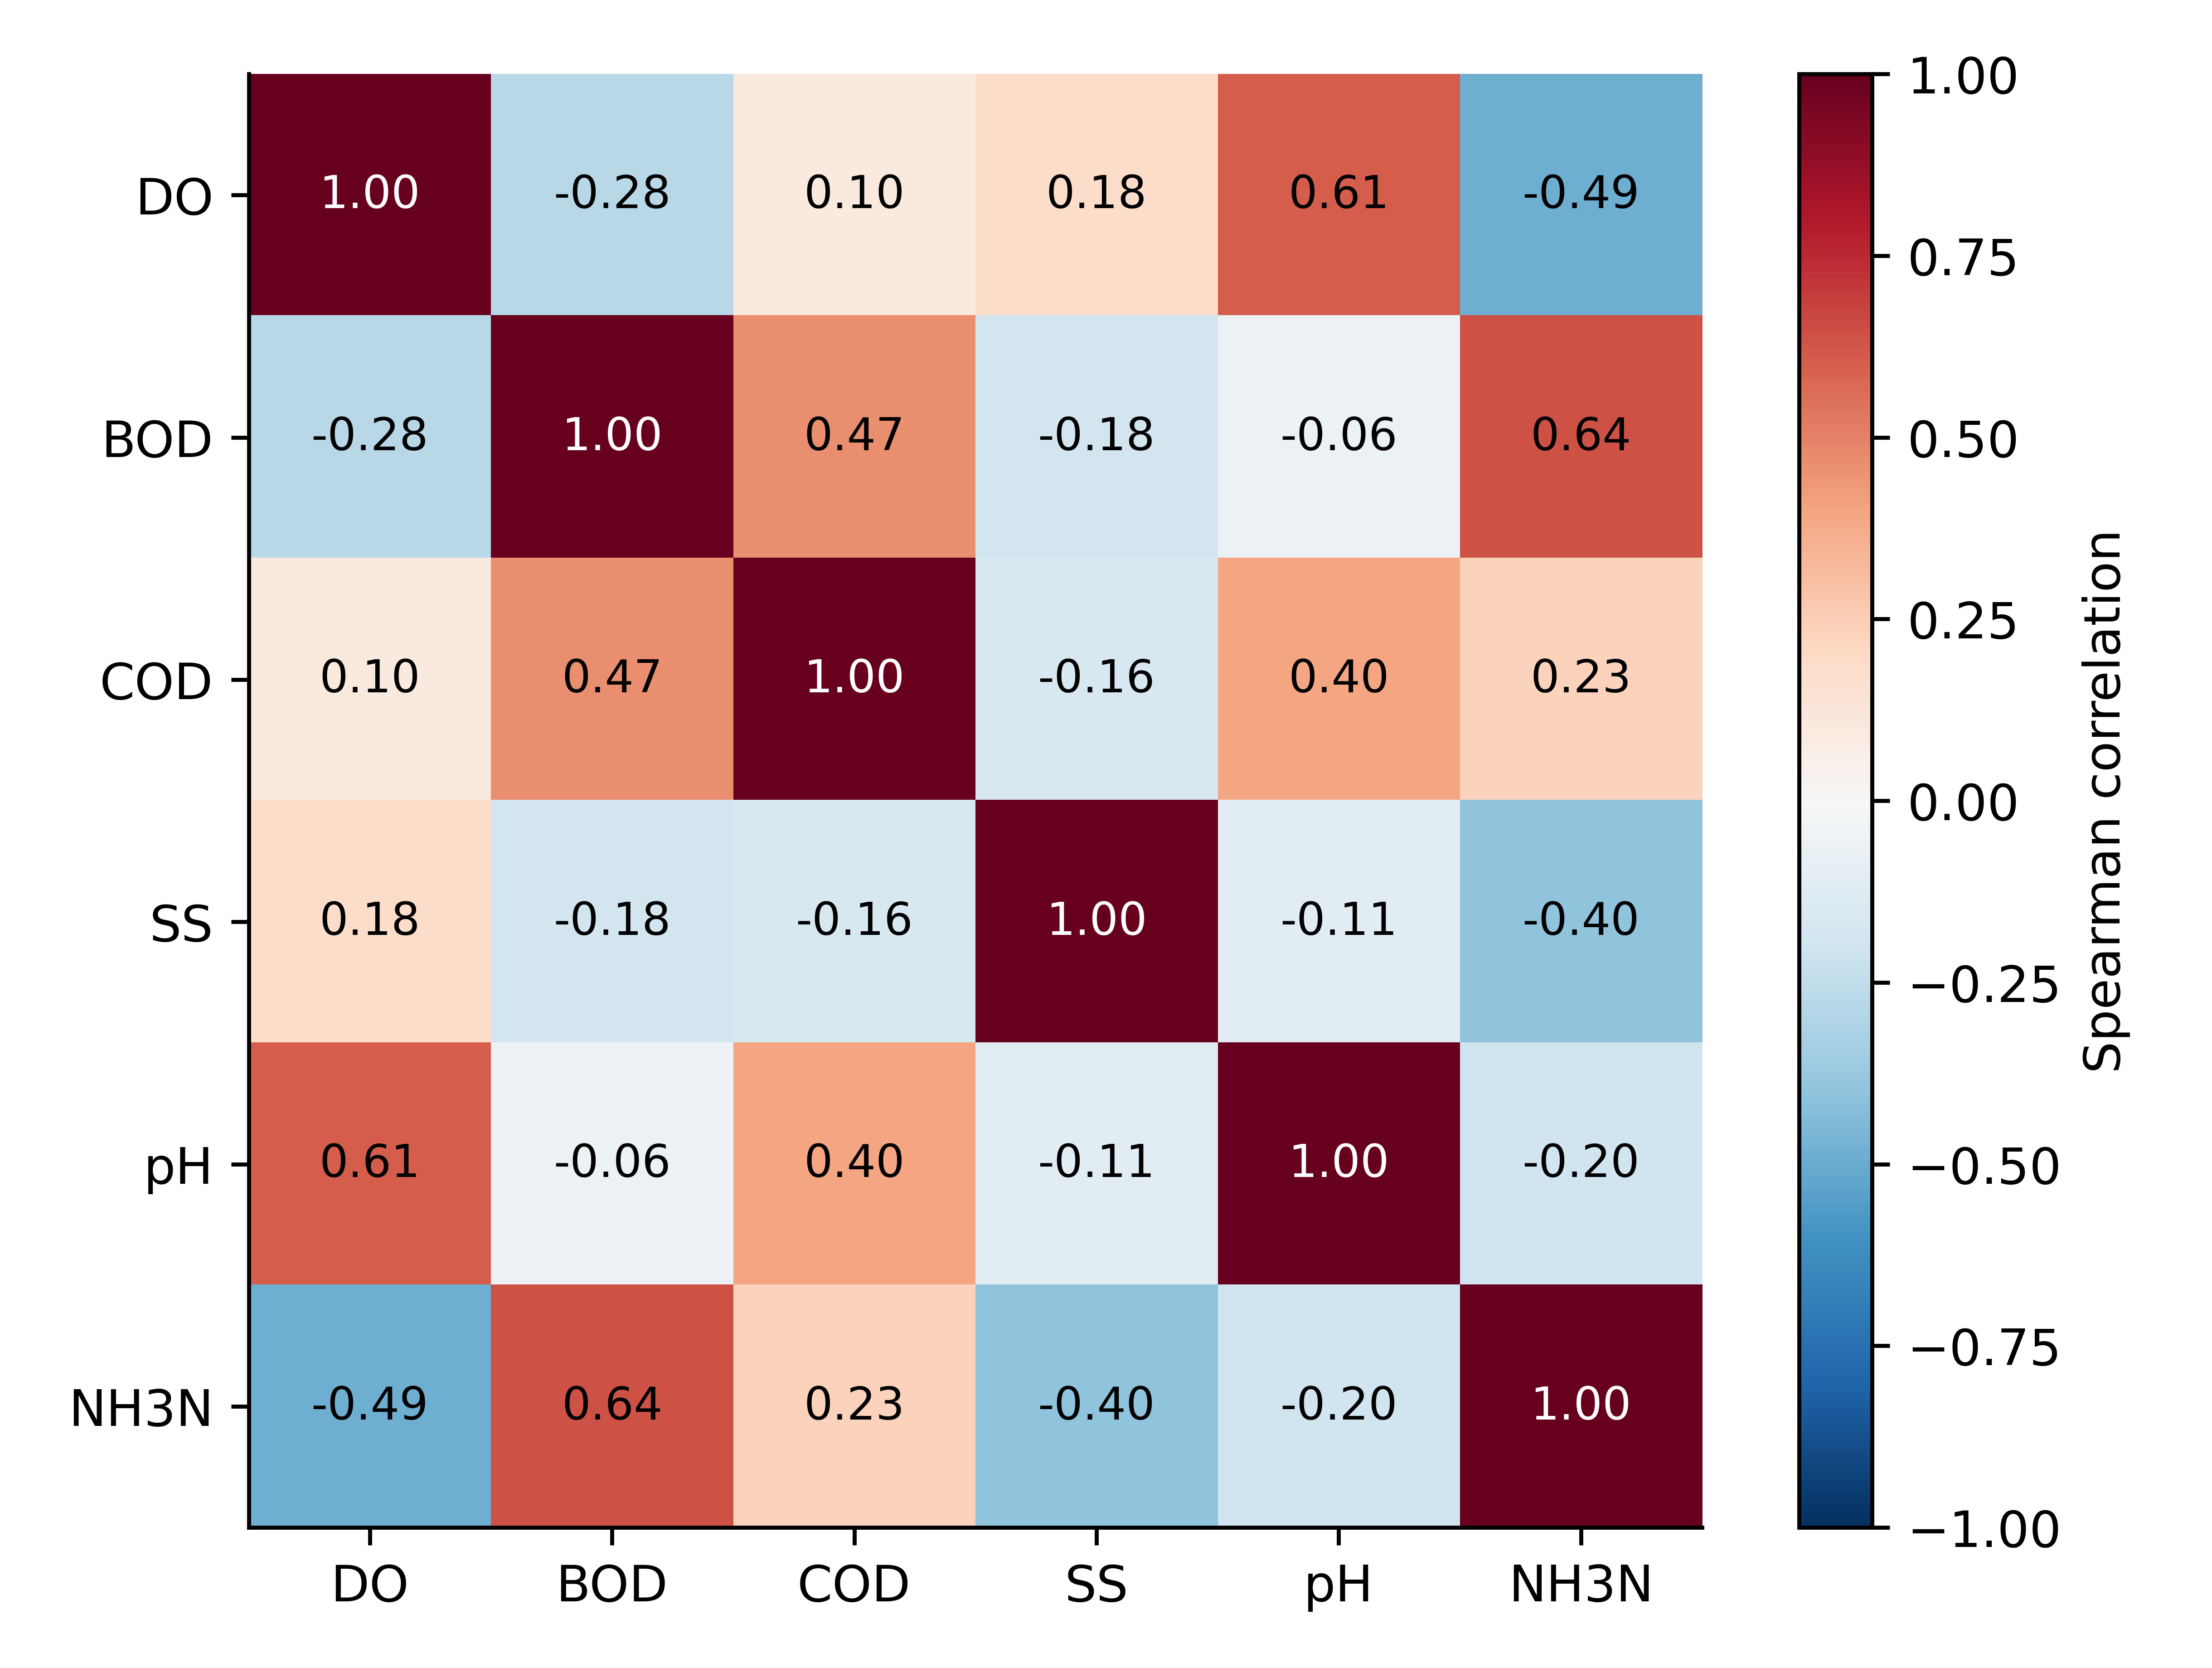

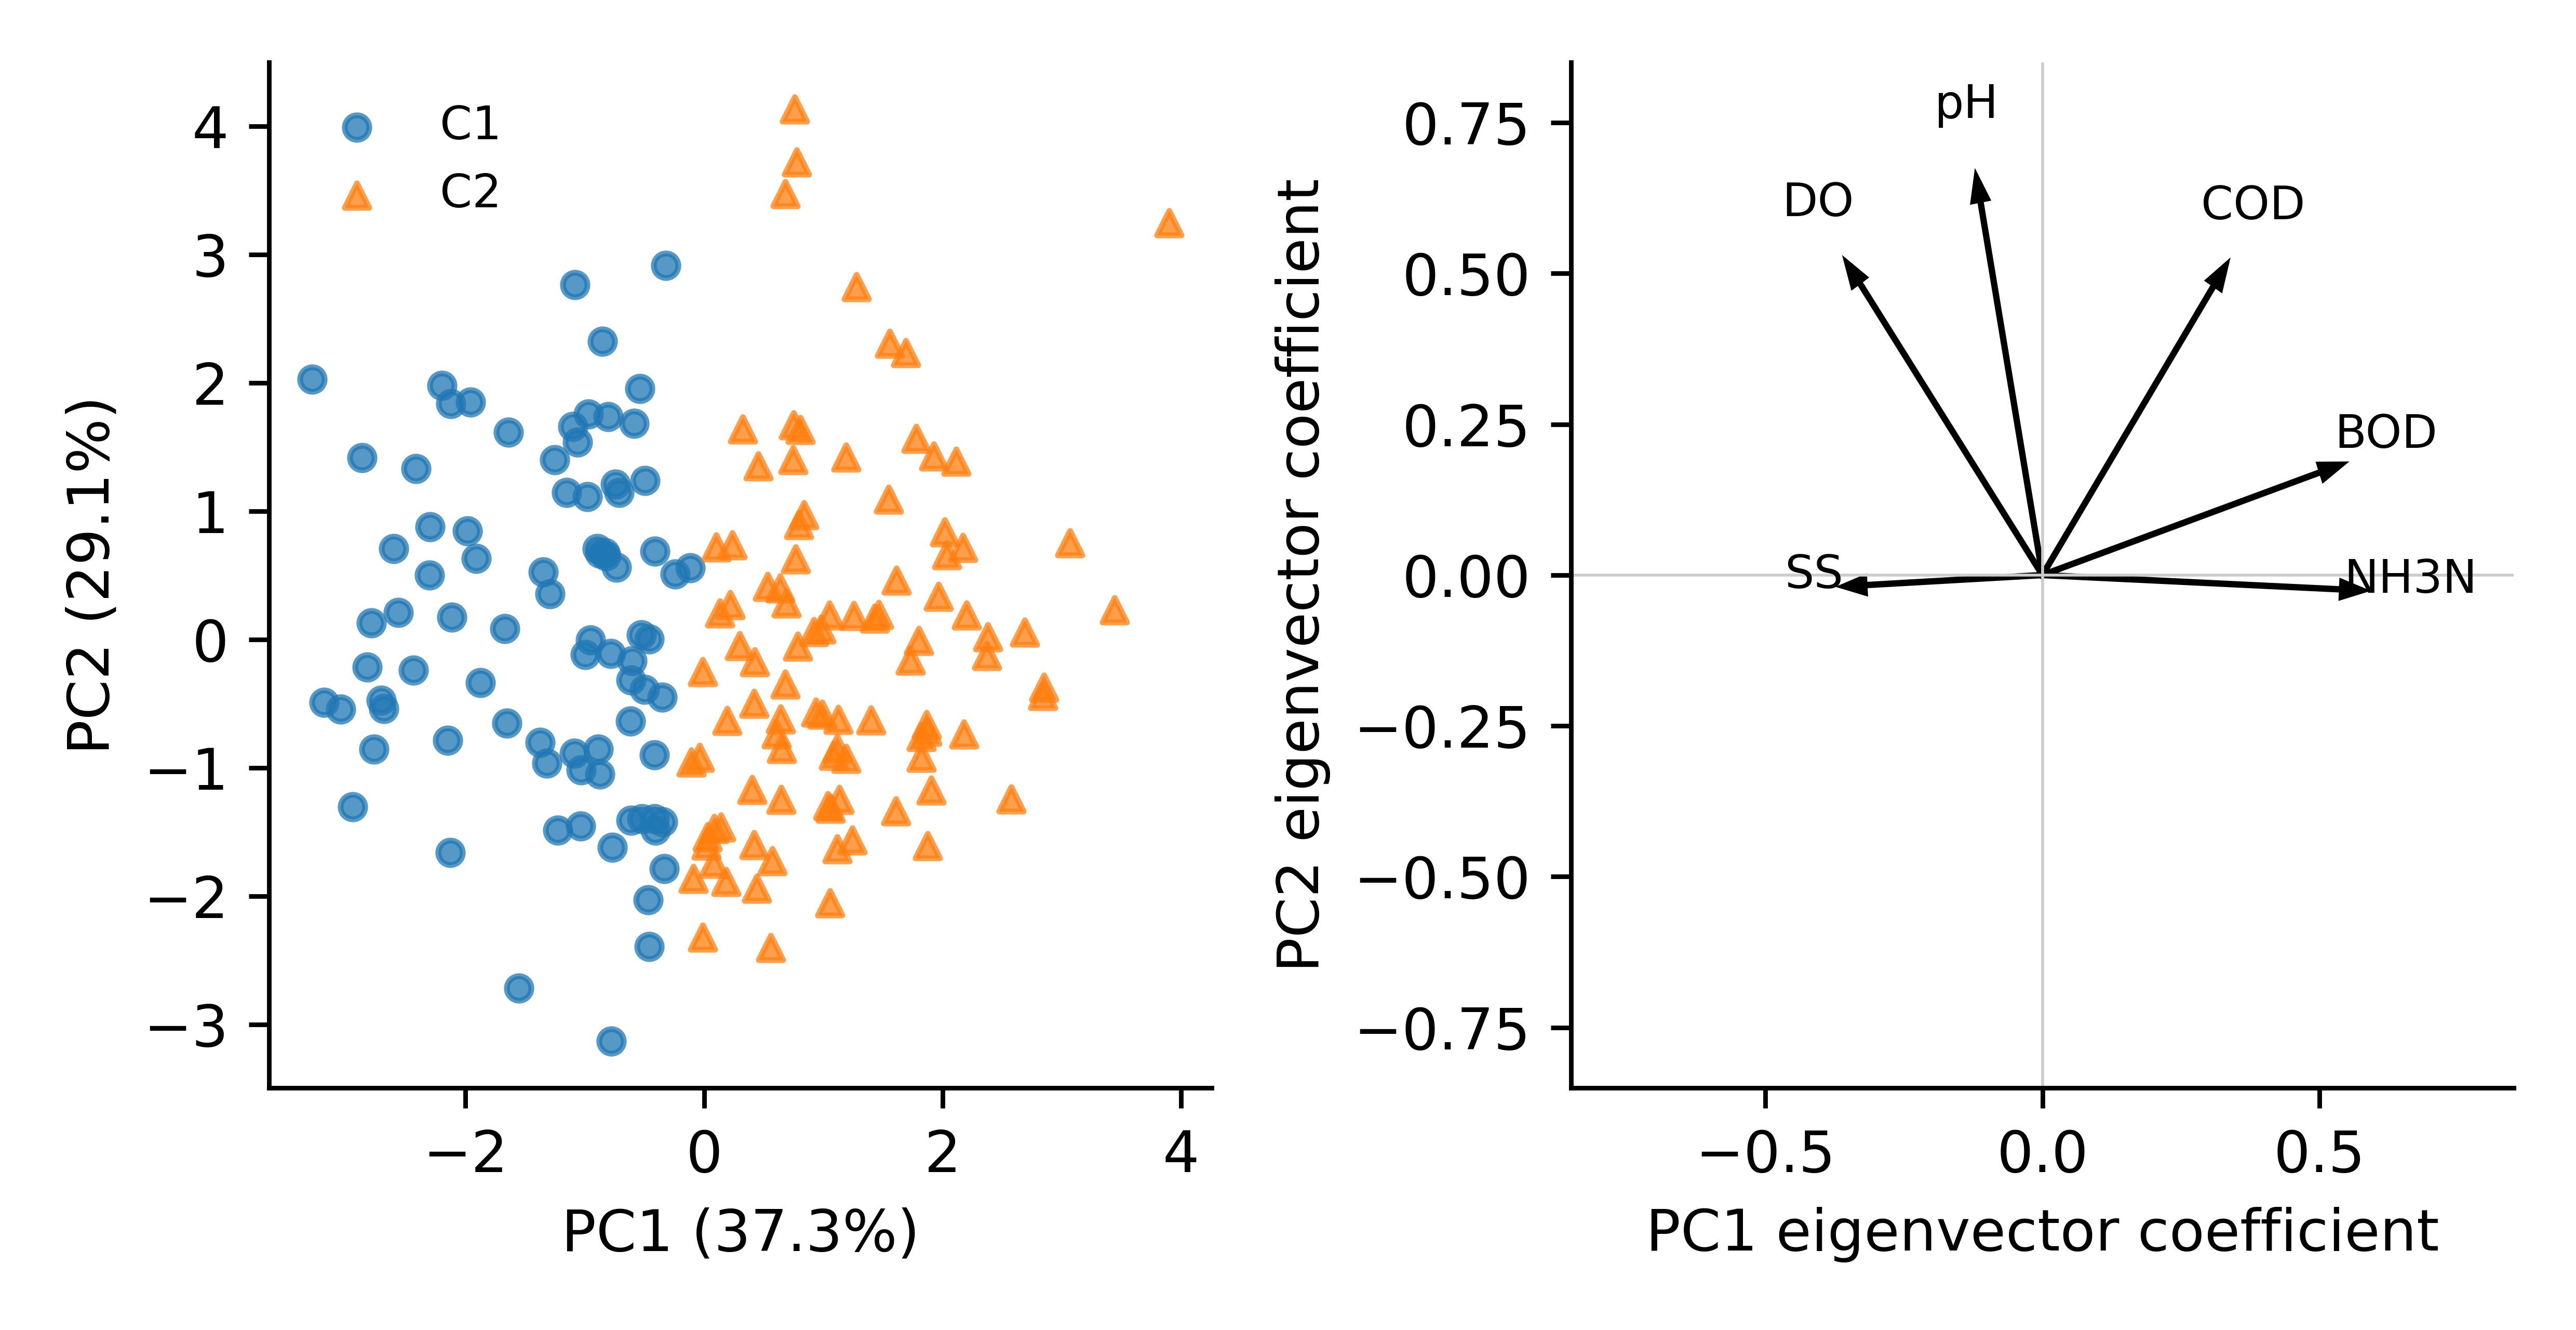

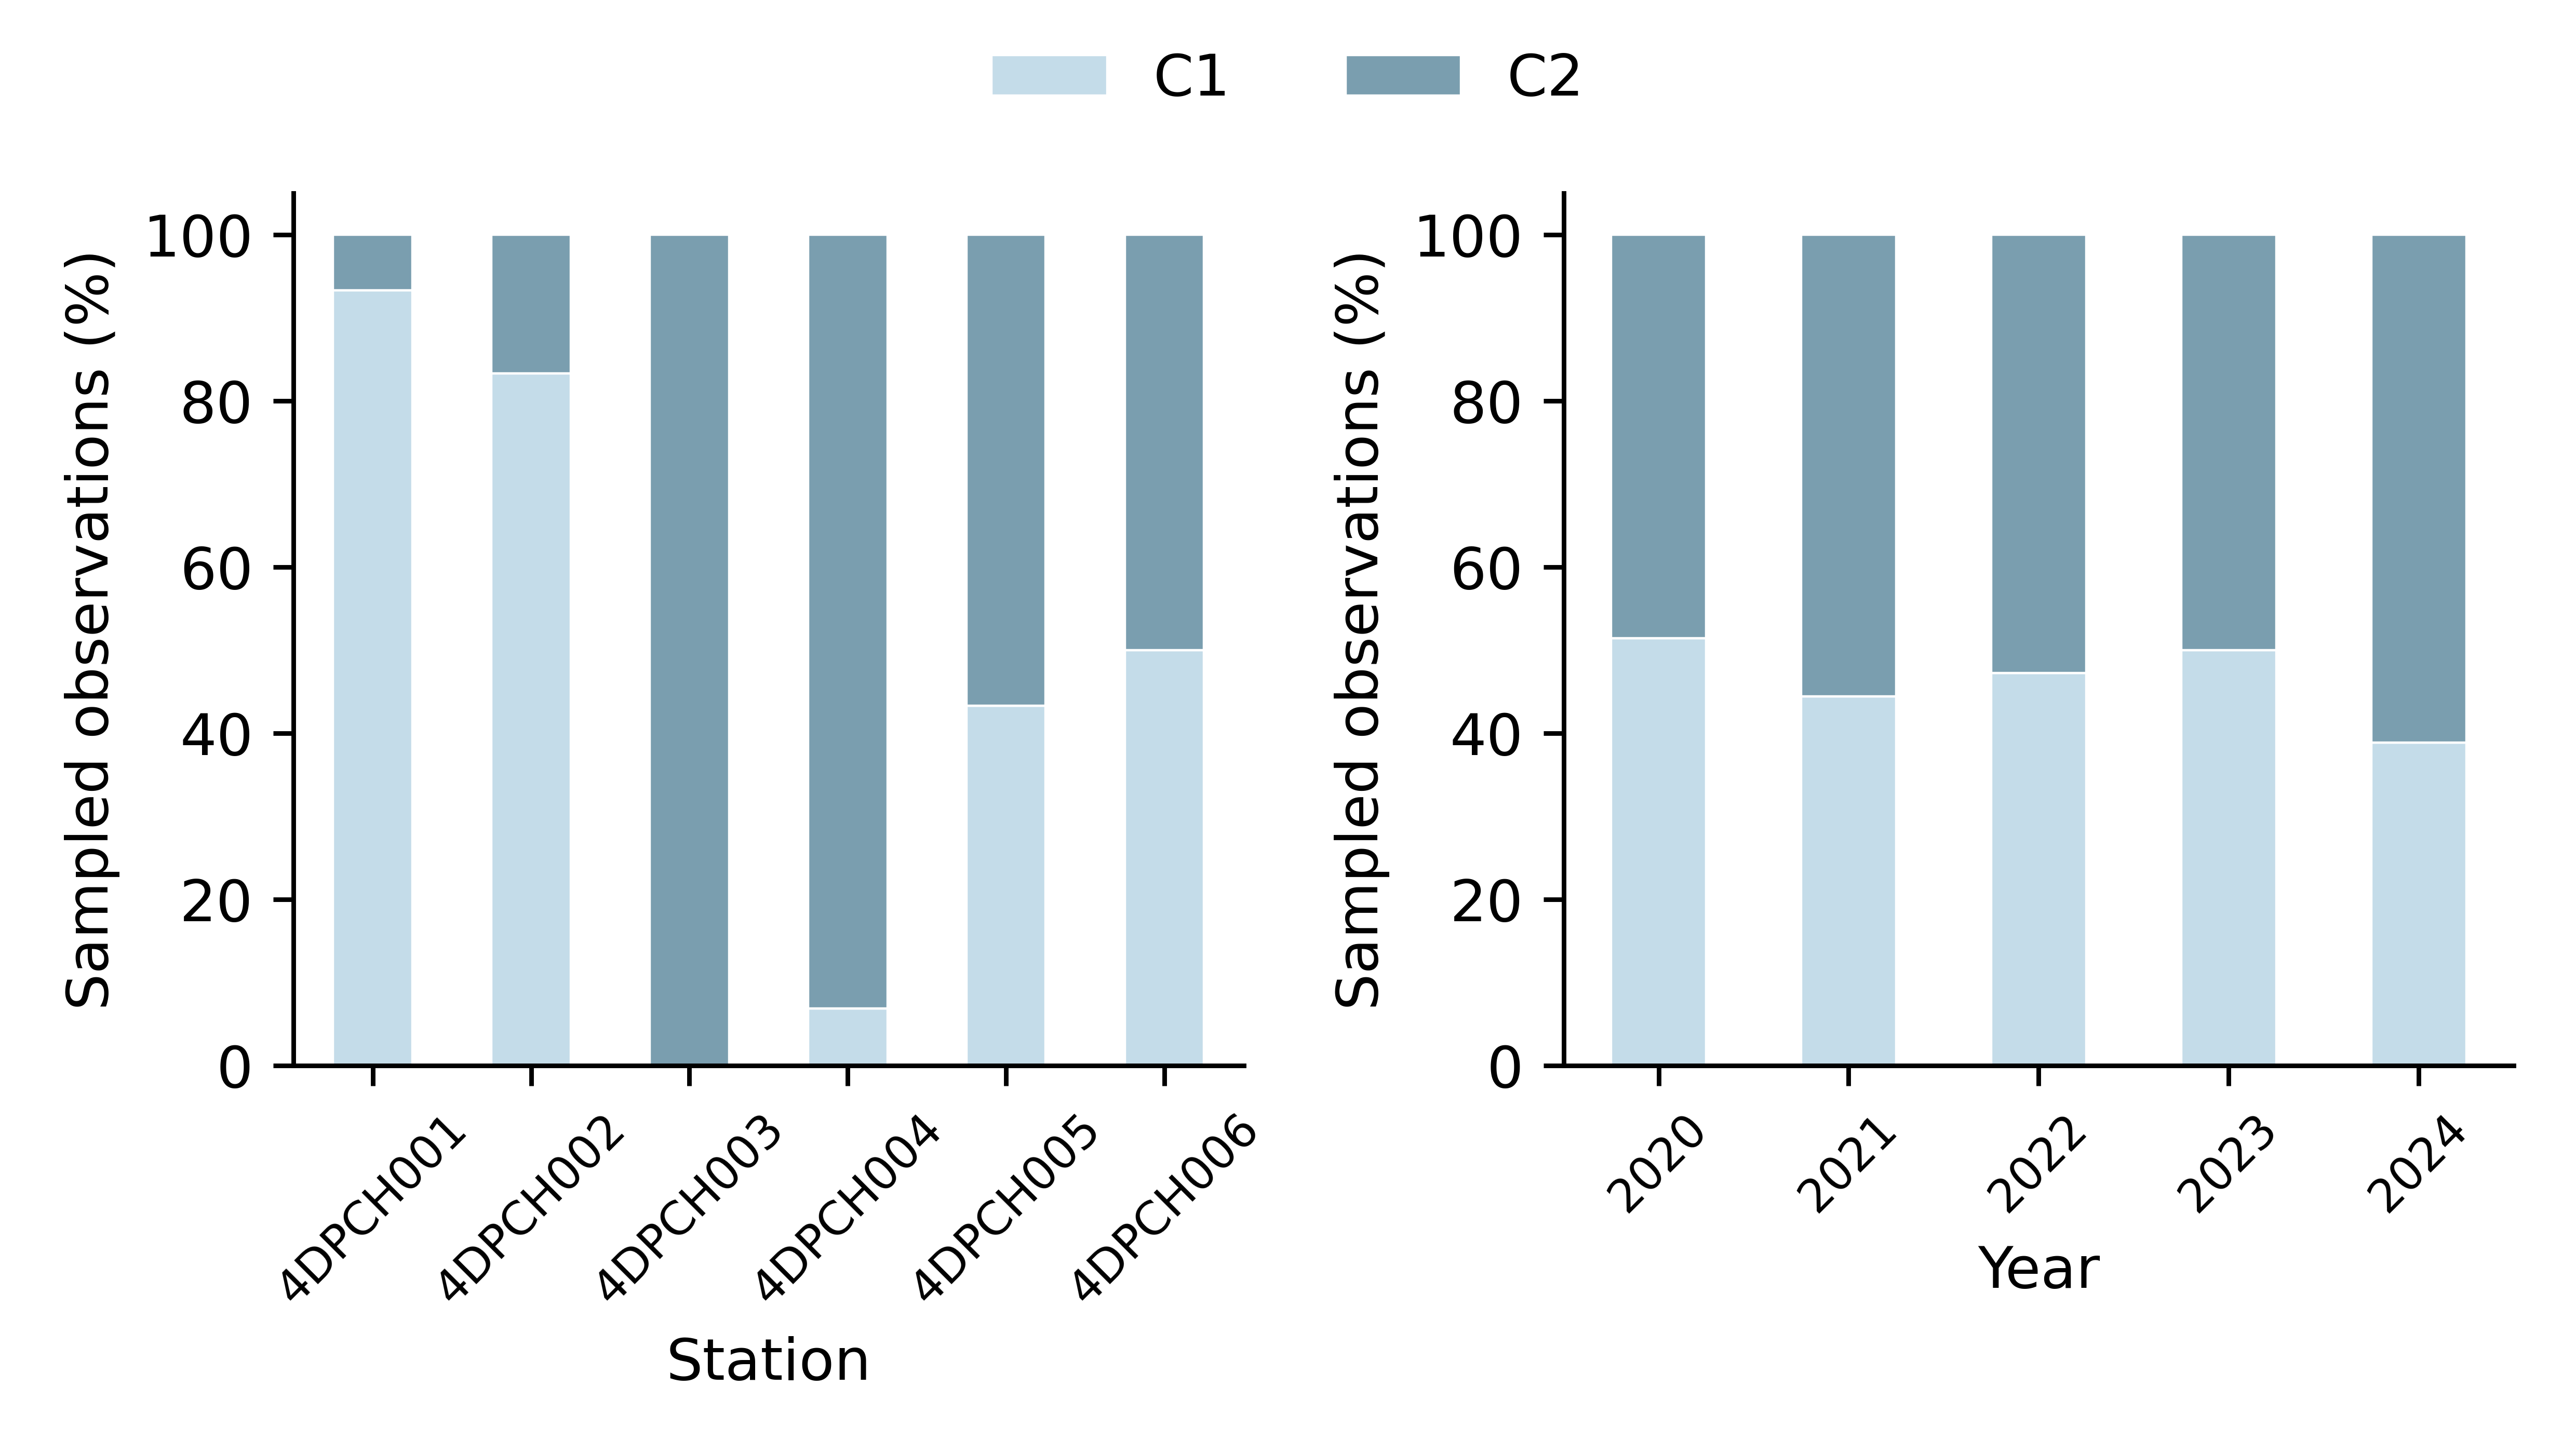

In [14]:
for name in ['figure1_correlation.png','figure2_pca.png','figure3_composition.png']:
    display(Image(filename=str(OUT/name), width=850))

## 11 Reproducibility record
Record IDs map results to the source workbook. Software versions and the source-file checksum are saved automatically.

In [15]:
import json
print((OUT/'run_metadata.json').read_text())
display(pd.read_csv(OUT/'cluster_assignments.csv').head())

{
  "n_source": 180,
  "n_complete": 179,
  "n_stations": 6,
  "n_dates": 30,
  "primary_method": "K-means",
  "repeats": 200,
  "censor_draws": 100,
  "gap_references": 200,
  "hopkins_repeats": 500,
  "sdo_grid_seeds": 30,
  "gap_selected_k": 1,
  "seed": 20261010,
  "source_sha256": "3b70f8ae9498205af30dee62667b971b899e00dfa6f3103c6ec9e080c03723be",
  "python": "3.11.0",
  "numpy": "2.3.5",
  "pandas": "2.2.3",
  "scipy": "1.17.0",
  "sklearn": "1.5.2",
  "sdoclust_external": true
}


,record_id,station,location,river,date,year,DO,BOD,COD,SS,pH,NH3N,SDOclust,K-means,Ward,cluster,PC1,PC2
0,1,4DPCH001,Jambatan Kampung Tok Sadang,RAJA GALI,2020-02-21,2020,6.404,4.0,29,79.0,7.435,0.54,0,0,1,1,-0.713676,1.147689
1,2,4DPCH001,Jambatan Kampung Tok Sadang,RAJA GALI,2020-06-21,2020,5.225,6.0,28,103.0,7.264,0.36,0,0,1,1,-0.410925,0.690193
2,3,4DPCH001,Jambatan Kampung Tok Sadang,RAJA GALI,2020-08-23,2020,6.322,2.0,38,12.0,8.669,0.01,0,0,1,1,-1.080289,2.763299
3,4,4DPCH001,Jambatan Kampung Tok Sadang,RAJA GALI,2020-10-21,2020,5.375,1.0,16,0.5,6.972,0.25,0,0,1,1,-0.498657,-0.387574
4,5,4DPCH001,Jambatan Kampung Tok Sadang,RAJA GALI,2020-11-27,2020,4.836,2.0,24,21.0,6.798,0.26,0,0,1,1,-0.613805,-0.317273
